<img align="right" src="https://panoptes-uploads.zooniverse.org/project_avatar/86c23ca7-bbaa-4e84-8d8a-876819551431.png" type="image/png" height=100 width=100>
</img>
<h1 align="left">Cover Summary (Segmentation Post-processing)</h1>
<h4 align="left">Written by the KSO Team</h4>

Builds a one-page benthic-cover summary from `coverage_by_frame.csv` (output of `Model_Inference_Segmentation.ipynb`). It is the segmentation analogue of the bounding-box detection report.

Panels:
- Cover along the transect (absolute per-class frame cover over time)
- Relative cover composition and a per-class breakdown
- Cover intensity along the transect

`coverage_frac` is per class with overlapping instances of the same class merged, so each class is 0 to 100% of the frame. The line plot and intensity map use these absolute cover values directly. Classes can overlap each other, so only the composition donut is normalised across classes; it is not total vegetation cover.

Edit Phase 1, then run all cells. The figure renders inline and is saved as PDF and PNG.

---
## Phase 1: Configuration

In [1]:
from pathlib import Path

# Inputs
RUN_DIR = Path(
    "/scratch/project_465002425/ferfersv/inference/skane/LST_skane_100E_11s_1.5_conf0.001_stride1_conf30"
)
COV_CSV = RUN_DIR / "coverage_by_frame.csv"
DET_CSV = RUN_DIR / "all_detections.csv"
OUT_PDF = RUN_DIR / "cover_summary.pdf"
OUT_PNG = RUN_DIR / "cover_summary.png"

# Video sampling. These must match the inference run.
FPS = 30.0
STRIDE = 1
BIN_S = 5.0

# Figure text and class order
TITLE = "Skane transect - benthic macroalgae cover"  # Edit for each survey/run.
TIME_LABEL = "Time in transect (s)"
CLASSES = ["Fucus sp.", "Algal turf", "Filamentous algae"]

# ColourBrewer Dark2-inspired subset: clear class separation and close to the
# earlier Stenshuvud figure.
COLORS = {
    "Fucus sp.": "#D95F02",
    "Algal turf": "#7570B3",
    "Filamentous algae": "#1B9E77",
}

# Training and deployment provenance. Edit these for each model/run.
TRAIN_SPLIT = (155,44,22)
MODEL_NAME = "YOLO11n-seg"
DEPLOY_CONF = 0.30
TEST_MAP50 = 0.503
TEST_PER_CLASS = {
    "Fucus sp.": 0.806,
    "Algal turf": 0.396,
    "Filamentous algae": 0.308,
}

assert COV_CSV.is_file(), f"coverage_by_frame.csv not found: {COV_CSV}"
if DET_CSV is not None:
    DET_CSV = Path(DET_CSV)

print("Coverage CSV:", COV_CSV)
print("Output:      ", OUT_PDF)


Coverage CSV: /scratch/project_465002425/ferfersv/inference/skane/LST_skane_100E_11s_1.5_conf0.001_stride1_conf30/coverage_by_frame.csv
Output:       /scratch/project_465002425/ferfersv/inference/skane/LST_skane_100E_11s_1.5_conf0.001_stride1_conf30/cover_summary.pdf


---
## Phase 2: Build the figure

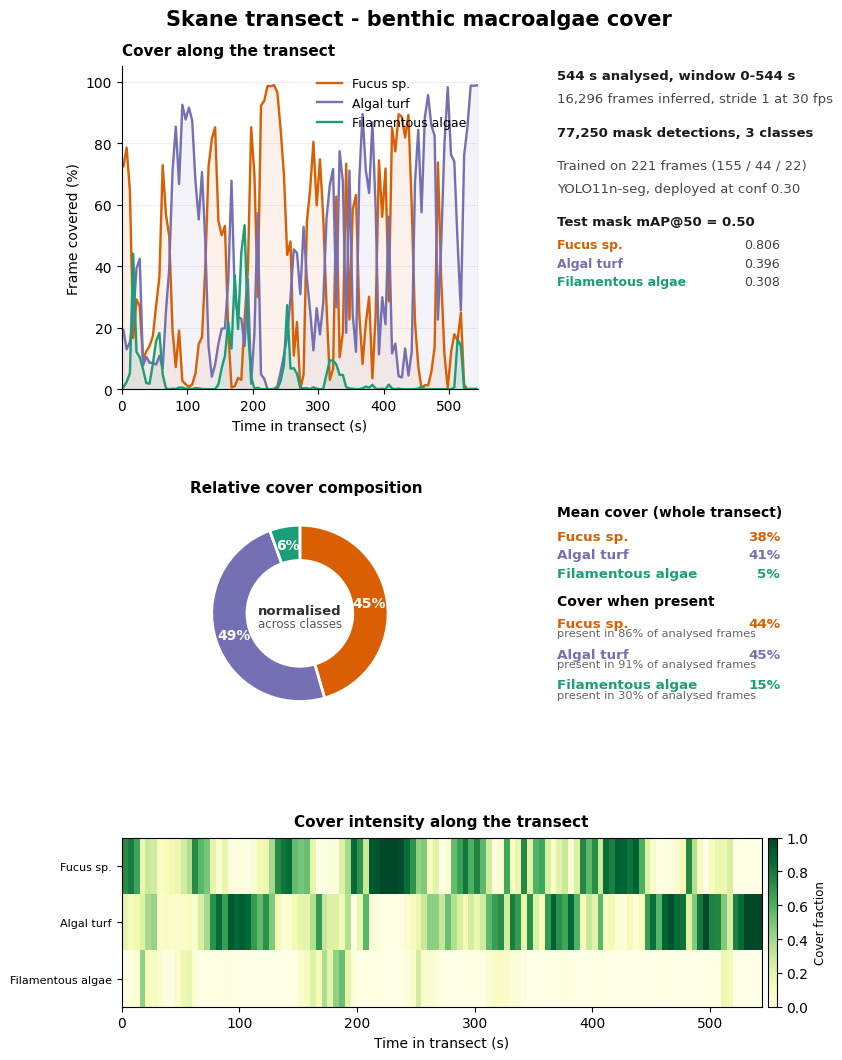

Saved: /scratch/project_465002425/ferfersv/inference/skane/LST_skane_100E_11s_1.5_conf0.001_stride1_conf30/cover_summary.pdf
Saved: /scratch/project_465002425/ferfersv/inference/skane/LST_skane_100E_11s_1.5_conf0.001_stride1_conf30/cover_summary.png
Mean cover %: {'Fucus sp.': np.float64(38.1), 'Algal turf': np.float64(41.0), 'Filamentous algae': np.float64(4.6)}


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec

cov = pd.read_csv(COV_CSV)

# Build a zero-filled sampled-frame grid.
fmax = int(cov["frame"].max())
grid = np.arange(0, fmax + STRIDE, STRIDE)
piv = (
    cov.pivot_table(
        index="frame",
        columns="class_name",
        values="coverage_frac",
        aggfunc="max",
    )
    .reindex(grid)
    .reindex(columns=CLASSES)
    .fillna(0.0)
)

# Prefer timestamps written by inference. This preserves original video time
# if a clip was trimmed. Fall back to frame / FPS for older CSVs.
if "timestamp_s" in cov.columns:
    time_by_frame = cov.groupby("frame")["timestamp_s"].first().reindex(grid)
    fallback_time = pd.Series(grid / FPS, index=grid)
    t = time_by_frame.fillna(fallback_time).to_numpy(dtype=float)
else:
    t = grid / FPS

t_min = float(np.nanmin(t))
t_max = float(np.nanmax(t))
dur_s = max(0.0, t_max - t_min)
total_frames = len(piv)

mean_cov = {c: piv[c].mean() * 100 for c in CLASSES}
cond_cov = {
    c: (
        piv.loc[piv[c] > 0, c].mean() * 100
        if (piv[c] > 0).any()
        else 0.0
    )
    for c in CLASSES
}
pres = {c: (piv[c] > 0).mean() * 100 for c in CLASSES}

n_det = None
if DET_CSV is not None and DET_CSV.is_file():
    n_det = len(pd.read_csv(DET_CSV, usecols=["frame"]))

# Bin for plotting. Values remain absolute frame-cover fractions; only the
# composition donut below is normalised across classes. Use bin centres for the
# line plot.
bin_id = np.floor((t - t_min) / BIN_S).astype(int)
binned = piv.groupby(bin_id)[CLASSES].mean()
bin_t = t_min + (binned.index.to_numpy(dtype=float) + 0.5) * BIN_S

plt.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
    }
)

fig = plt.figure(figsize=(8.5, 11.0), facecolor="white")
gs = gridspec.GridSpec(
    3,
    2,
    height_ratios=[3.15, 2.15, 1.65],
    width_ratios=[3.05, 1.95],
    hspace=0.48,
    wspace=0.27,
    left=0.15,
    right=0.93,
    top=0.92,
    bottom=0.065,
)

fig.suptitle(TITLE, fontsize=15, fontweight="bold", y=0.972)

# Cover over time
ax1 = fig.add_subplot(gs[0, 0])
for c in CLASSES:
    y = binned[c].to_numpy() * 100
    ax1.plot(bin_t, y, color=COLORS[c], lw=1.7, label=c)
    ax1.fill_between(bin_t, 0, y, color=COLORS[c], alpha=0.08)

ax1.set_xlim(t_min, t_max)
ax1.set_ylim(0, 105)
ax1.set_yticks(np.arange(0, 101, 20))
ax1.set_xlabel(TIME_LABEL)
ax1.set_ylabel("Frame covered (%)")
ax1.set_title("Cover along the transect", loc="left", pad=8)
ax1.legend(frameon=False, fontsize=9, loc="upper right")
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="y", alpha=0.20)

# Provenance and model evaluation
ax2 = fig.add_subplot(gs[0, 1])
ax2.axis("off")
mins, secs = int(dur_s // 60), int(round(dur_s % 60))
if secs == 60:
    mins += 1
    secs = 0

train_total = sum(TRAIN_SPLIT)
provenance = [
    (
        f"{dur_s:.0f} s analysed, window {t_min:.0f}-{t_max:.0f} s",
        True,
        "0.10",
    ),
    (
        f"{total_frames:,} frames inferred, stride {STRIDE} at {FPS:.0f} fps",
        False,
        "0.28",
    ),
    ("", False, "0.28"),
    (
        (
            f"{n_det:,} mask detections, {len(CLASSES)} classes"
            if n_det is not None
            else f"{len(CLASSES)} classes"
        ),
        True,
        "0.10",
    ),
    ("", False, "0.28"),
    (
        "Trained on "
        f"{train_total:,} frames ({TRAIN_SPLIT[0]} / {TRAIN_SPLIT[1]} / "
        f"{TRAIN_SPLIT[2]})",
        False,
        "0.28",
    ),
    (
        f"{MODEL_NAME}, deployed at conf {DEPLOY_CONF:.2f}",
        False,
        "0.28",
    ),
    ("", False, "0.28"),
    (f"Test mask mAP@50 = {TEST_MAP50:.2f}", True, "0.10"),
]

y = 0.99
for text, bold, color in provenance:
    ax2.text(
        0.0,
        y,
        text,
        fontsize=9.5,
        fontweight="bold" if bold else "normal",
        color=color,
        va="top",
        ha="left",
        transform=ax2.transAxes,
        wrap=True,
    )
    y -= 0.071 if text else 0.032

for c in CLASSES:
    score = TEST_PER_CLASS.get(c)
    if score is None:
        continue
    ax2.text(
        0.0,
        y,
        c,
        fontsize=9.0,
        fontweight="bold",
        color=COLORS[c],
        va="top",
        transform=ax2.transAxes,
    )
    ax2.text(
        0.98,
        y,
        f"{score:.3f}",
        fontsize=9.0,
        color="0.25",
        va="top",
        ha="right",
        transform=ax2.transAxes,
    )
    y -= 0.058

# Relative composition donut
ax3 = fig.add_subplot(gs[1, 0])
shares = np.array([mean_cov[c] for c in CLASSES], dtype=float)
if shares.sum() > 0:
    ax3.pie(
        shares,
        colors=[COLORS[c] for c in CLASSES],
        startangle=90,
        counterclock=False,
        autopct="%1.0f%%",
        pctdistance=0.79,
        wedgeprops={"width": 0.40, "edgecolor": "white", "linewidth": 2},
        textprops={"color": "white", "fontsize": 10, "fontweight": "bold"},
    )
    ax3.text(
        0,
        0.03,
        "normalised",
        ha="center",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color="0.18",
    )
    ax3.text(
        0,
        -0.11,
        "across classes",
        ha="center",
        va="center",
        fontsize=8.5,
        color="0.35",
    )
else:
    ax3.text(0.5, 0.5, "No cover detected", ha="center", va="center")

ax3.set_title("Relative cover composition", loc="left", pad=8)

# Per-class cover summary
ax4 = fig.add_subplot(gs[1, 1])
ax4.axis("off")
ax4.text(
    0.0,
    0.99,
    "Mean cover (whole transect)",
    fontsize=10,
    fontweight="bold",
    va="top",
    transform=ax4.transAxes,
)

y = 0.88
for c in CLASSES:
    ax4.text(
        0.0,
        y,
        c,
        fontsize=9.7,
        color=COLORS[c],
        fontweight="bold",
        va="top",
        transform=ax4.transAxes,
    )
    ax4.text(
        0.98,
        y,
        f"{mean_cov[c]:.0f}%",
        fontsize=9.7,
        color=COLORS[c],
        fontweight="bold",
        va="top",
        ha="right",
        transform=ax4.transAxes,
    )
    y -= 0.085

y -= 0.035
ax4.text(
    0.0,
    y,
    "Cover when present",
    fontsize=10,
    fontweight="bold",
    va="top",
    transform=ax4.transAxes,
)
y -= 0.105

for c in CLASSES:
    ax4.text(
        0.0,
        y,
        c,
        fontsize=9.7,
        color=COLORS[c],
        fontweight="bold",
        va="top",
        transform=ax4.transAxes,
    )
    ax4.text(
        0.98,
        y,
        f"{cond_cov[c]:.0f}%",
        fontsize=9.7,
        color=COLORS[c],
        fontweight="bold",
        va="top",
        ha="right",
        transform=ax4.transAxes,
    )
    y -= 0.052
    ax4.text(
        0.0,
        y,
        f"present in {pres[c]:.0f}% of analysed frames",
        fontsize=8.2,
        color="0.40",
        va="top",
        transform=ax4.transAxes,
    )
    y -= 0.088

# Coverage intensity map
ax5 = fig.add_subplot(gs[2, :])
H = binned[CLASSES].to_numpy().T
im = ax5.imshow(
    H,
    aspect="auto",
    cmap="YlGn",
    vmin=0,
    vmax=1,
    extent=[t_min, t_max, len(CLASSES) - 0.5, -0.5],
    interpolation="nearest",
)
ax5.set_yticks(range(len(CLASSES)))
ax5.set_yticklabels(CLASSES, fontsize=8)
ax5.set_xlabel(TIME_LABEL)
ax5.set_title("Cover intensity along the transect", pad=8)
cb = fig.colorbar(im, ax=ax5, fraction=0.025, pad=0.01)
cb.set_label("Cover fraction", fontsize=8.5)

fig.savefig(OUT_PDF, facecolor="white")
fig.savefig(OUT_PNG, dpi=160, facecolor="white")
plt.show()

print("Saved:", OUT_PDF)
print("Saved:", OUT_PNG)
print("Mean cover %:", {c: round(mean_cov[c], 1) for c in CLASSES})


---
## Done

Outputs `cover_summary.pdf` and `cover_summary.png` in the run folder.

For a new inference run, update the Phase 1 paths, sampling settings, `TITLE`, and provenance fields. The line plot and intensity map remain on the original 0 to 100% frame-cover scale; only the composition donut is normalised across classes. Keep evaluation metrics from a test run evaluated at `conf=0.001`; `DEPLOY_CONF` is the separate inference operating point.